# Fase 2 · Parte 1: marco inferencial, independencia y contrastes de proporciones

**Proyecto Integrador de Ciencia de Datos · Grupo 4**
Asociación entre cobertura de seguro médico y enfermedad reciente en Paraguay (EPHC 2024)

**Responsable de esta parte:** Kyara Ivanna Popov Araujo

| Parte | Contenido | Código propio | Responsable |
|---|---|---|---|
| **1** | Correcciones de la Fase 1, marco inferencial, independencia de las observaciones, **H1** (seguro) y **H5** (área) | `src/fase2/datos.py`, `src/fase2/remuestreo.py`, `src/fase2/unir_notebooks.py` | Kyara Ivanna Popov Araujo |
| 2 | **H2** (edad) y **H4** (educación e ingreso) | `src/fase2/supuestos.py`, `src/fase2/efectos.py` | Zinri Alice Bobadilla Peralta |
| 3 | **H3** (quintil de ingreso), **H6** (seguro controlando otras variables), comparaciones múltiples, tabla resumen y conclusión | `src/fase2/resumen.py` | Alejandro Sanabria Penayo |

Los tres notebooks se ejecutan en orden (1, 2, 3). Cada uno guarda sus resultados en `output/fase2/` y la Parte 3 los reúne en la tabla resumen.

In [1]:
import sys
from pathlib import Path

# El notebook vive en /notebooks; se agrega la raíz del repositorio para importar src/.
RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import confint_proportions_2indep, proportions_ztest

from src.fase2 import datos, efectos, remuestreo, supuestos

pd.set_option("display.float_format", lambda v: f"{v:.3e}" if 0 < abs(v) < 1e-4 else f"{v:,.4f}")
datos.aplicar_estilo()

df = datos.cargar_datos()
registro = datos.RegistroContrastes(parte=1)

print(f"Registros: {len(df):,} | Hogares: {df['hogar_id'].nunique():,} | UPM: {df['UPM'].nunique():,}")
print(f"Nivel de significancia: {datos.ALFA} | Semilla: {datos.SEMILLA} | Réplicas bootstrap: {datos.N_BOOTSTRAP}")

Registros: 57,109 | Hogares: 17,186 | UPM: 1,750
Nivel de significancia: 0.05 | Semilla: 42 | Réplicas bootstrap: 2000


## 1. Correcciones aplicadas a la Fase 1

No se recibió devolución del docente sobre la Fase 1. Las correcciones siguientes surgen de una revisión propia de la Fase 1 completa, hecha antes de iniciar la inferencia:

| N.º | Qué se encontró | Corrección aplicada |
|---|---|---|
| 1 | En `docs/` había una segunda copia de `ephc_salud_2024_limpio.csv` generada con una versión anterior de la base (otro factor de expansión). Difería del dataset reproducible en el factor, en 9.497 ingresos y en 4.882 quintiles. | Se eliminó la copia de `docs/`. El único dataset válido es `data/processed/ephc_salud_2024_limpio.csv`, que el notebook de la Fase 1 regenera desde `data/raw/`. |
| 2 | El diccionario del informe de la Fase 1 tomó dos datos de esa copia obsoleta: rango del factor de expansión "10,26 a 889,47" y quintil 1 con 22,05 % de la muestra. | Valores correctos, verificados abajo: factor de expansión entero de 9 a 894; quintil 1 con 24,05 % de la muestra. |
| 3 | `README.md`, `bitacora_limpieza.csv` y `diccionario_datos_final.csv` todavía decían que `tiene_seguro = 1` para los códigos "1 a 6 u 8" de `S01A`. El código 8 no existe. | Se corrigieron los tres archivos: `tiene_seguro = 1` para `S01A` de 1 a 6 y 0 para `S01A = 7`. El código y los resultados no cambian. |
| 4 | La hipótesis preliminar 4 (educación e ingreso) incluía a niños y adolescentes, cuyos años de estudio están limitados por la edad. | En la Fase 2 la hipótesis se evalúa en personas de 25 años o más. El valor con todas las edades se informa como referencia en la Parte 2. |
| 5 | La Fase 1 trató la edad como una variable de efecto lineal. | Se agrega `grupo_edad` (seis tramos) porque la relación entre edad y enfermedad tiene forma de U (Parte 2). Se construye por código en `src/fase2/datos.py`, sin modificar el CSV de la Fase 1. |
| 6 | La Fase 1 afirmó que no era posible medir la enfermedad por trimestre, porque los archivos trimestrales no traen `S01A` ni `S03`. | Los cuatro archivos trimestrales contienen exactamente las mismas 57.744 personas que la base anual. Al enlazarlos por la clave de persona se recupera el **trimestre de entrevista** de cada una, y con él la proporción de enfermedad por trimestre (sección 3.1). La variable `trimestre` se construye por código en `src/fase2/datos.py`. |
| 7 | Faltaba `statsmodels` en `requirements.txt`. | Se agregó, junto con las instrucciones de reproducción de la Fase 2 en el `README.md`. |

La celda siguiente verifica empíricamente los puntos 1, 2, 3 y 6 sobre el dataset que se usa en toda la fase.

In [2]:
verificacion = pd.Series({
    "Registros del dataset analítico": f"{len(df):,}",
    "Clave persona_id única": df["persona_id"].is_unique,
    "Códigos presentes en seguro_codigo (S01A)": sorted(df["seguro_codigo"].unique().tolist()),
    "tiene_seguro = 1 equivale a S01A entre 1 y 6": bool((df["tiene_seguro"] == df["seguro_codigo"].between(1, 6).astype(int)).all()),
    "Rango de factor_expansion": f"{df['factor_expansion'].min()} a {df['factor_expansion'].max()}",
    "Quintil 1 (% de la muestra)": round(df["quintil_ingreso"].eq(1).mean() * 100, 2),
    "Copia obsoleta en docs/ eliminada": not (RAIZ / "docs" / "ephc_salud_2024_limpio.csv").exists(),
    "Personas con trimestre de entrevista recuperado": f"{df['trimestre'].notna().sum():,} de {len(df):,}",
    "UPM entrevistadas en más de un trimestre": int((df.groupby("UPM")["trimestre"].nunique() > 1).sum()),
}, name="resultado")
verificacion.to_frame()

,resultado
Registros del dataset analítico,"57,109"
Clave persona_id única,True
Códigos presentes en seguro_codigo (S01A),"[1, 2, 3, 4, 5, 6, 7]"
tiene_seguro = 1 equivale a S01A entre 1 y 6,True
Rango de factor_expansion,9 a 894
Quintil 1 (% de la muestra),24.0500
Copia obsoleta en docs/ eliminada,True
Personas con trimestre de entrevista recuperado,"57,109 de 57,109"
UPM entrevistadas en más de un trimestre,0


## 2. Marco inferencial (declarado antes de ejecutar las pruebas)

El nivel de significancia, las hipótesis, la regla de decisión y el criterio de corrección se fijaron antes de ejecutar las pruebas. La única decisión tomada a la vista de los datos fue usar la edad en tramos en H6, después de observar en H2 que su relación con la enfermedad no es lineal; se deja constancia de ello.

**Nivel de significancia:** α = 0,05 para toda la fase. Pruebas bilaterales, salvo H4, cuya dirección ya estaba enunciada en la Fase 1.

**Hipótesis.** Las cinco hipótesis preliminares de la Fase 1 se contrastan tal como fueron enunciadas. Se agrega H6, que surge de la conclusión de la Fase 1: comprobar si el patrón principal se mantiene al considerar otras variables.

| | En lenguaje natural | H0 | H1 | Familia de prueba |
|---|---|---|---|---|
| **H1** | La proporción de enfermedad reciente difiere entre personas con y sin seguro. | π_con = π_sin | π_con ≠ π_sin | Comparar dos proporciones |
| **H2** | La edad de quienes enfermaron difiere de la de quienes no enfermaron. | P(edad_enf > edad_sano) = 0,5 | P(edad_enf > edad_sano) ≠ 0,5 | Comparar dos grupos independientes |
| **H3** | La enfermedad reciente no se distribuye igual entre los quintiles de ingreso. | Enfermedad y quintil son independientes | Existe asociación | Asociación entre dos categóricas |
| **H4** | A más años de estudio, mayor ingreso per cápita (25 años o más). | ρ ≤ 0 | ρ > 0 | Significancia de una correlación |
| **H5** | La proporción de enfermedad reciente difiere entre el área rural y la urbana. | π_rural = π_urbana | π_rural ≠ π_urbana | Comparar dos proporciones |
| **H6** | La asociación entre seguro y enfermedad se mantiene al controlar edad, sexo, área y quintil. | β_seguro = 0 (OR ajustado = 1) | β_seguro ≠ 0 | Efecto de una variable controlando otras |

Se cubren cinco familias distintas de pruebas.

**Comparaciones múltiples.** Se realizan seis contrastes confirmatorios. Si cada uno se evaluara por separado con α = 0,05 y todas las hipótesis nulas fueran ciertas, la probabilidad de obtener al menos un falso positivo sería 1 − 0,95⁶ = 26,5 %. Por eso la decisión final usa valores p ajustados por **Bonferroni** sobre los seis contrastes (equivale a exigir p < 0,0083). Las diez comparaciones post hoc entre quintiles (H3) son exploratorias y se ajustan por **Benjamini-Hochberg**. Las pruebas de supuestos (Shapiro-Wilk, Levene) no son contrastes de las hipótesis de investigación y no entran en la corrección.

**Regla de decisión.** Como se muestra en la sección 3, las observaciones no son independientes. Por lo tanto, la decisión de cada contraste se toma con el **valor p robusto a conglomerados**, ajustado por Bonferroni. El valor p clásico (que supone independencia) se informa siempre al lado para transparencia.

**Uso del factor de expansión.** Las pruebas se aplican sobre la muestra sin ponderar, porque las pruebas clásicas no admiten pesos muestrales sin un tratamiento de diseño complejo. Para la hipótesis principal (H1) se agrega la estimación ponderada como análisis de sensibilidad.

## 3. Supuesto de independencia de las observaciones

Todas las pruebas clásicas suponen que cada observación es independiente de las demás. La EPHC selecciona unidades primarias de muestreo (UPM), luego viviendas, y entrevista a **todos** los integrantes de cada hogar. Las personas de un mismo hogar comparten ingreso, entorno y contagios, así que el supuesto debe verificarse y no darse por cumplido.

Se mide con la **correlación intraclase (ICC)**: qué proporción de la variabilidad total se explica por pertenecer al mismo conglomerado. Con independencia, ICC ≈ 0. El **efecto de diseño** indica cuántas veces más grande es la varianza real respecto de la que supone una muestra aleatoria simple.

In [3]:
filas = []
for variable, etiqueta in [("enfermedad_reciente", "Enfermedad reciente"), ("tiene_seguro", "Tiene seguro")]:
    for nivel, columna in [("Hogar", "hogar_id"), ("UPM", "UPM")]:
        r = remuestreo.correlacion_intraclase(df[variable], df[columna])
        filas.append({"Variable": etiqueta, "Conglomerado": nivel, **r})

tabla_icc = pd.DataFrame(filas).rename(columns={
    "conglomerados": "N.º de conglomerados", "tamano_medio": "Personas por conglomerado",
    "icc": "ICC", "efecto_diseno": "Efecto de diseño",
})
tabla_icc.round(3)

,Variable,Conglomerado,N.º de conglomerados,Personas por conglomerado,ICC,Efecto de diseño
0,Enfermedad reciente,Hogar,17186,3.3230,0.3060,1.7120
1,Enfermedad reciente,UPM,1750,32.6340,0.0550,2.7470
2,Tiene seguro,Hogar,17186,3.3230,0.5710,2.3260
3,Tiene seguro,UPM,1750,32.6340,0.1810,6.7410


**Resultado y decisión.** El supuesto de independencia **no se cumple**:

- Dentro del hogar la enfermedad reciente tiene ICC = 0,31: si una persona del hogar enfermó, es mucho más probable que otra también. El seguro está todavía más concentrado por hogar (ICC = 0,57).
- A nivel de UPM el ICC de la enfermedad es 0,055, pero como cada UPM aporta unas 33 personas, el efecto de diseño es 2,7: la varianza real de la prevalencia es casi el triple de la que supone una muestra aleatoria simple.

Consecuencia: los errores estándar clásicos quedan subestimados y los valores p clásicos son demasiado optimistas. Siguiendo la regla de pasar a una alternativa cuando un supuesto falla, **cada contraste se acompaña de una versión que no supone independencia**:

- error estándar robusto a conglomerados (agrupado por UPM, que contiene a los hogares), o
- bootstrap por conglomerados: se remuestrean UPM completas en lugar de personas.

La decisión final usa esa versión robusta.

### 3.1 Dependencia temporal: trimestre de entrevista

Otra fuente posible de dependencia es el momento de la entrevista: las personas entrevistadas en la misma época comparten estación del año y brotes. La Fase 1 no pudo evaluarlo. Con el trimestre recuperado (corrección 6) ahora es posible describirlo. No es un contraste de hipótesis adicional: se muestran las proporciones con sus intervalos.

,Personas,UPM,Enfermedad reciente (%),IC 95 % inf.,IC 95 % sup.,"Enfermedad, ponderada (%)",Con seguro (%),Área rural (%)
Trimestre,,,,,,,,
T1,13790,416,27.4300,26.3400,28.6300,26.8300,26.0200,40.6600
T2,13933,417,32.0500,30.5100,33.4600,30.2000,26.8400,40.6800
T3,13219,416,32.5800,31.3100,33.9200,31.4100,26.6900,41.3000
T4,16167,501,28.4900,27.3400,29.6500,27.5300,26.3600,46.0600


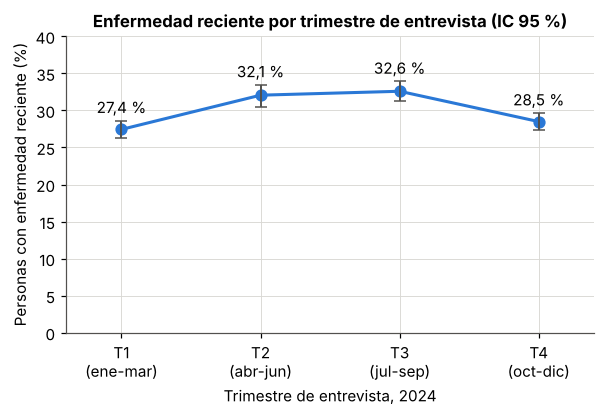

In [4]:
filas = []
for t in range(1, 5):
    mascara = (df["trimestre"] == t).to_numpy()
    r = remuestreo.ic_bootstrap(np.mean, df["enfermedad_reciente"].to_numpy()[mascara],
                                conglomerados=df.loc[mascara, "UPM"], n_rep=1000)
    filas.append({
        "Trimestre": f"T{t}",
        "Personas": int(mascara.sum()),
        "UPM": df.loc[mascara, "UPM"].nunique(),
        "Enfermedad reciente (%)": r["estimacion"] * 100,
        "IC 95 % inf.": r["inf"] * 100,
        "IC 95 % sup.": r["sup"] * 100,
        "Enfermedad, ponderada (%)": np.average(df.loc[mascara, "enfermedad_reciente"], weights=df.loc[mascara, "factor_expansion"]) * 100,
        "Con seguro (%)": df.loc[mascara, "tiene_seguro"].mean() * 100,
        "Área rural (%)": (df.loc[mascara, "area"] == "Rural").mean() * 100,
    })
por_trimestre = pd.DataFrame(filas).set_index("Trimestre")
por_trimestre.to_csv(datos.ruta_salida("enfermedad_por_trimestre.csv"))
display(por_trimestre.round(2))

fig, eje = plt.subplots(figsize=(6.2, 3.5))
x = np.arange(4)
eje.plot(x, por_trimestre["Enfermedad reciente (%)"], color=datos.AZUL, linewidth=2, marker="o", markersize=7)
eje.errorbar(x, por_trimestre["Enfermedad reciente (%)"],
             yerr=[por_trimestre["Enfermedad reciente (%)"] - por_trimestre["IC 95 % inf."],
                   por_trimestre["IC 95 % sup."] - por_trimestre["Enfermedad reciente (%)"]],
             fmt="none", color=datos.GRIS, capsize=4, linewidth=1.3)
for xi, v, sup in zip(x, por_trimestre["Enfermedad reciente (%)"], por_trimestre["IC 95 % sup."]):
    eje.annotate(f"{v:.1f} %".replace(".", ","), (xi, sup), xytext=(0, 5), textcoords="offset points", ha="center")
eje.set_xticks(x, ["T1\n(ene-mar)", "T2\n(abr-jun)", "T3\n(jul-sep)", "T4\n(oct-dic)"])
eje.set_xlim(-0.4, 3.4)
eje.set_ylim(0, 40)
eje.set_xlabel("Trimestre de entrevista, 2024")
eje.set_ylabel("Personas con enfermedad reciente (%)")
eje.set_title("Enfermedad reciente por trimestre de entrevista (IC 95 %)")
datos.guardar_figura(fig, "f2_09_enfermedad_por_trimestre.png")
plt.show()

**Interpretación del gráfico.** La proporción de enfermedad reciente es 27,4 % en las entrevistas del primer trimestre y 28,5 % en las del cuarto, frente a 32,1 % y 32,6 % en las del segundo y el tercero. Como la pregunta se refiere a los 90 días anteriores, las entrevistas de mitad de año cubren el otoño y el invierno. Los intervalos de los trimestres centrales no se superponen con los de los extremos: hay un patrón estacional de entre 3,6 y 5,2 puntos porcentuales según el par de trimestres, mayor que la diferencia entre áreas.

**Consecuencias para la inferencia.**

- Cada UPM se entrevistó en un único trimestre. La dependencia que el trimestre introduce dentro de cada UPM queda cubierta por los errores robustos y el bootstrap por UPM. La que podría introducir entre UPM distintas del mismo trimestre se comprueba agregando el trimestre como control en H5 y en un modelo de sensibilidad de H6.
- El trimestre podría confundir una comparación si los grupos estuvieran repartidos de forma desigual en el año. No es el caso del seguro: la proporción de personas aseguradas es casi la misma en los cuatro trimestres (entre 26,0 % y 26,8 %). En H6 se agrega el trimestre en un modelo de sensibilidad (M4) para comprobarlo. El área sí está repartida de forma algo desigual (46,1 % de la muestra del cuarto trimestre es rural, frente a alrededor de 41 % en los otros tres), lo que se tiene en cuenta en H5.
- La base tiene componente temporal, lo que condiciona el diseño de la Fase 3 (ver conclusión).

## 4. H1: cobertura de seguro y enfermedad reciente

- **H0:** π_con = π_sin. La proporción de personas con enfermedad reciente es igual con y sin seguro.
- **H1:** π_con ≠ π_sin. La proporción difiere (bilateral, α = 0,05).

**Selección de la prueba.** Las dos variables son binarias y los grupos son independientes entre sí (cada persona pertenece a uno solo). Se comparan dos proporciones, por lo que corresponde la **prueba z de dos proporciones**. Para dos grupos es equivalente al chi-cuadrado de una tabla 2×2 (χ² = z²), pero la prueba z entrega directamente el intervalo de confianza de la diferencia, que es lo que responde la pregunta de investigación.

### 4.1 Verificación de supuestos

In [5]:
tabla_h1 = pd.crosstab(df["cobertura"], df["enfermedad"]).loc[["Con seguro", "Sin seguro"], ["Enfermo/a", "Sano/a"]]
exitos_h1 = tabla_h1["Enfermo/a"].to_numpy()
totales_h1 = tabla_h1.sum(axis=1).to_numpy()

print("Tabla de contingencia (frecuencias observadas)")
display(tabla_h1)
print("Condición de tamaño para la aproximación normal (al menos 10 éxitos y 10 fracasos por grupo)")
supuestos.condicion_proporciones(exitos_h1, totales_h1, tabla_h1.index)

Tabla de contingencia (frecuencias observadas)


enfermedad,Enfermo/a,Sano/a
cobertura,,
Con seguro,4382,10736
Sin seguro,12780,29211


Condición de tamaño para la aproximación normal (al menos 10 éxitos y 10 fracasos por grupo)


,n,exitos,fracasos,proporcion,cumple
cobertura,,,,,
Con seguro,15118,4382,10736,0.2899,True
Sin seguro,41991,12780,29211,0.3044,True


| Supuesto | Verificación | Resultado |
|---|---|---|
| Variable de respuesta binaria | `enfermedad_reciente` vale 0 o 1 | Se cumple |
| Grupos independientes entre sí | Cada persona está en un solo grupo | Se cumple |
| Tamaño suficiente para la aproximación normal | Mínimo observado: 4.382 éxitos | Se cumple con amplio margen |
| Independencia de las observaciones dentro de cada grupo | ICC por hogar 0,31; efecto de diseño por UPM 2,7 (sección 3) | **No se cumple** |

**Decisión:** se ejecuta la prueba z clásica y, por el incumplimiento de la independencia, se repite con error estándar robusto a conglomerados. La conclusión se basa en la versión robusta.

### 4.2 Ejecución de la prueba

In [6]:
p_con, p_sin = exitos_h1 / totales_h1

# Prueba z clásica (varianza combinada bajo H0) e IC de Wald para la diferencia
z_h1, p_clasico_h1 = proportions_ztest(exitos_h1, totales_h1, alternative="two-sided")
ic_wald_h1 = confint_proportions_2indep(exitos_h1[0], totales_h1[0], exitos_h1[1], totales_h1[1],
                                        method="wald", compare="diff", alpha=1 - datos.NIVEL_CONFIANZA)

# Versión robusta: mismo estimador, error estándar agrupado por UPM
robusta_h1 = remuestreo.diferencia_proporciones_robusta(df["enfermedad_reciente"], df["tiene_seguro"], df["UPM"])

# Tamaños del efecto
medidas_h1 = efectos.medidas_2x2(*tabla_h1.to_numpy().ravel())
magnitud_h1 = efectos.magnitud(medidas_h1["h"], "h")

pd.DataFrame({
    "Clásica (supone independencia)": {
        "Diferencia (con − sin), en p.p.": (p_con - p_sin) * 100,
        "Error estándar, en p.p.": (ic_wald_h1[1] - ic_wald_h1[0]) / (2 * 1.959964) * 100,
        "Estadístico z": z_h1,
        "Valor p": p_clasico_h1,
        "IC 95 % inferior, en p.p.": ic_wald_h1[0] * 100,
        "IC 95 % superior, en p.p.": ic_wald_h1[1] * 100,
    },
    "Robusta a conglomerados (UPM)": {
        "Diferencia (con − sin), en p.p.": robusta_h1["diferencia"] * 100,
        "Error estándar, en p.p.": robusta_h1["error_estandar"] * 100,
        "Estadístico z": robusta_h1["z"],
        "Valor p": robusta_h1["p"],
        "IC 95 % inferior, en p.p.": robusta_h1["inf"] * 100,
        "IC 95 % superior, en p.p.": robusta_h1["sup"] * 100,
    },
})

,Clásica (supone independencia),Robusta a conglomerados (UPM)
"Diferencia (con − sin), en p.p.",-1.4498,-1.4498
"Error estándar, en p.p.",0.4319,0.5663
Estadístico z,-3.3339,-2.5600
Valor p,0.0009,0.0105
"IC 95 % inferior, en p.p.",-2.2964,-2.5597
"IC 95 % superior, en p.p.",-0.6032,-0.3398


In [7]:
print(f"Proporción con seguro: {p_con:.4f} | sin seguro: {p_sin:.4f}")
print(f"h de Cohen: {medidas_h1['h']:.4f} ({magnitud_h1})")
print(f"Riesgo relativo: {medidas_h1['riesgo_relativo']:.4f} | Razón de odds: {medidas_h1['razon_odds']:.4f}")
print(f"Umbral de Bonferroni para {datos.N_CONTRASTES} contrastes: {datos.ALFA / datos.N_CONTRASTES:.4f}")

Proporción con seguro: 0.2899 | sin seguro: 0.3044
h de Cohen: -0.0317 (trivial)
Riesgo relativo: 0.9524 | Razón de odds: 0.9329
Umbral de Bonferroni para 6 contrastes: 0.0083


### 4.3 Intervalo de confianza por bootstrap comparado con el clásico

El bootstrap estima el intervalo sin fórmula: se remuestrea la muestra con reemplazo 2.000 veces, se recalcula la diferencia de proporciones en cada réplica y se toman los percentiles 2,5 y 97,5. Se comparan cuatro intervalos para la misma diferencia:

1. **Clásico (Wald):** fórmula que supone independencia.
2. **Bootstrap simple:** remuestrea personas. Es el equivalente directo del clásico y debería coincidir con él.
3. **Bootstrap por conglomerados:** remuestrea UPM completas, respetando la dependencia dentro de hogares y UPM.
4. **Bootstrap por conglomerados ponderado:** igual al anterior, usando `factor_expansion` para estimar la diferencia poblacional.

In [8]:
def diferencia_proporciones(y, grupo):
    return y[grupo == 1].mean() - y[grupo == 0].mean()


def diferencia_proporciones_ponderada(y, grupo, peso):
    con, sin = grupo == 1, grupo == 0
    return np.average(y[con], weights=peso[con]) - np.average(y[sin], weights=peso[sin])


y, g, w = df["enfermedad_reciente"].to_numpy(), df["tiene_seguro"].to_numpy(), df["factor_expansion"].to_numpy()

boot_simple = remuestreo.ic_bootstrap(diferencia_proporciones, y, g)
boot_upm = remuestreo.ic_bootstrap(diferencia_proporciones, y, g, conglomerados=df["UPM"])
boot_upm_pond = remuestreo.ic_bootstrap(diferencia_proporciones_ponderada, y, g, w, conglomerados=df["UPM"])

comparacion_ic = pd.DataFrame([
    {"Método": "1. Clásico (Wald)", "Estimación": p_con - p_sin, "IC inferior": ic_wald_h1[0], "IC superior": ic_wald_h1[1]},
    {"Método": "2. Bootstrap simple (personas)", "Estimación": boot_simple["estimacion"], "IC inferior": boot_simple["inf"], "IC superior": boot_simple["sup"]},
    {"Método": "3. Bootstrap por conglomerados (UPM)", "Estimación": boot_upm["estimacion"], "IC inferior": boot_upm["inf"], "IC superior": boot_upm["sup"]},
    {"Método": "4. Bootstrap por conglomerados, ponderado", "Estimación": boot_upm_pond["estimacion"], "IC inferior": boot_upm_pond["inf"], "IC superior": boot_upm_pond["sup"]},
]).set_index("Método") * 100
comparacion_ic["Amplitud"] = comparacion_ic["IC superior"] - comparacion_ic["IC inferior"]
comparacion_ic.to_csv(datos.ruta_salida("h1_comparacion_intervalos.csv"))
comparacion_ic.round(2)

,Estimación,IC inferior,IC superior,Amplitud
Método,,,,
1. Clásico (Wald),-1.4500,-2.3000,-0.6000,1.6900
2. Bootstrap simple (personas),-1.4500,-2.2700,-0.5300,1.7400
3. Bootstrap por conglomerados (UPM),-1.4500,-2.5400,-0.3200,2.2200
"4. Bootstrap por conglomerados, ponderado",-1.3100,-2.4800,0.0100,2.4900


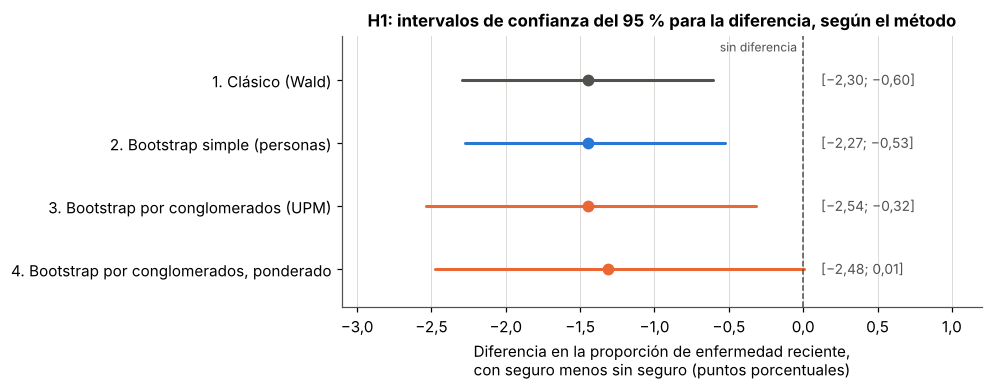

In [9]:
fig, eje = plt.subplots(figsize=(7.5, 3.2))
posiciones = np.arange(len(comparacion_ic))[::-1]
colores = [datos.GRIS, datos.AZUL, datos.NARANJA, datos.NARANJA]
for pos, (metodo, fila), color in zip(posiciones, comparacion_ic.iterrows(), colores):
    eje.plot([fila["IC inferior"], fila["IC superior"]], [pos, pos], color=color, linewidth=2, solid_capstyle="round")
    eje.scatter(fila["Estimación"], pos, color=color, s=45, zorder=3)
    eje.annotate(f"[{fila['IC inferior']:.2f}; {fila['IC superior']:.2f}]".replace(".", ",").replace("-", "−"),
                 (0.12, pos), va="center", fontsize=9, color=datos.GRIS)
eje.axvline(0, color=datos.GRIS, linewidth=1, linestyle="--")
eje.annotate("sin diferencia", (0, len(comparacion_ic) - 0.55), xytext=(-4, 0), textcoords="offset points",
             ha="right", fontsize=8, color=datos.GRIS)
eje.set_yticks(posiciones, comparacion_ic.index)
eje.set_ylim(-0.6, len(comparacion_ic) - 0.3)
eje.set_xlim(-3.1, 1.2)
eje.grid(axis="y", visible=False)
datos.ejes_con_coma(eje, decimales_x=1)
eje.set_xlabel("Diferencia en la proporción de enfermedad reciente,\ncon seguro menos sin seguro (puntos porcentuales)")
eje.set_title("H1: intervalos de confianza del 95 % para la diferencia, según el método")
datos.guardar_figura(fig, "f2_01_h1_intervalos_bootstrap.png")
plt.show()

**Interpretación del gráfico.** El bootstrap simple reproduce el intervalo clásico (ambos cerca de −2,3 a −0,6 puntos porcentuales): cuando se supone lo mismo, la fórmula y el remuestreo coinciden. Al remuestrear UPM completas el intervalo se ensancha alrededor de 30 % (−2,5 a −0,3), porque las personas de un mismo conglomerado aportan menos información independiente de la que su número sugiere. Con ponderación la diferencia estimada es algo menor (−1,31 p.p.) y el intervalo tiene una amplitud similar (−2,48 a 0,01). Su extremo superior queda en torno a cero y cambia levemente con la semilla, por lo que no se interpreta si lo incluye o no.

### 4.4 Registro e interpretación

In [10]:
z_boot_h1, p_boot_h1 = remuestreo.p_desde_error_estandar(boot_upm["estimacion"], boot_upm["error_estandar"])
print(f"Comprobación: valor p con el error estándar bootstrap por conglomerados = {p_boot_h1:.4f} "
      f"(analítico robusto = {robusta_h1['p']:.4f})")

registro.agregar(
    id="H1",
    hipotesis="La proporción de enfermedad reciente difiere entre personas con y sin seguro",
    variables="enfermedad_reciente × tiene_seguro",
    familia="Comparar dos proporciones",
    prueba="z de dos proporciones",
    supuestos="Tamaño: cumple. Independencia: no cumple (ICC hogar 0,31), se usa EE robusto por UPM",
    n=int(totales_h1.sum()),
    estadistico="z", valor_estadistico=z_h1, gl=np.nan,
    p_clasico=p_clasico_h1, p_robusto=robusta_h1["p"],
    efecto="h de Cohen", valor_efecto=medidas_h1["h"], magnitud=magnitud_h1,
    ic_parametro="Diferencia con − sin, en p.p.",
    ic_inf=boot_upm["inf"] * 100, ic_sup=boot_upm["sup"] * 100, ic_metodo="bootstrap por UPM",
)

Comprobación: valor p con el error estándar bootstrap por conglomerados = 0.0095 (analítico robusto = 0.0105)


**Resultado.** En la muestra, 28,99 % de las personas con seguro y 30,44 % de las personas sin seguro reportaron enfermedad reciente: una diferencia de −1,45 puntos porcentuales.

- **Análisis clásico:** z = −3,33; p = 0,0009. Si se supusiera independencia, la diferencia sería significativa incluso después de Bonferroni.
- **Análisis robusto a conglomerados:** z = −2,56; p = 0,010; IC 95 % por bootstrap de −2,54 a −0,32 p.p. El valor p es menor que 0,05, pero **no alcanza el umbral de Bonferroni** (0,0083). La decisión formal se toma en la Parte 3, junto con los demás contrastes.
- **Tamaño del efecto:** h de Cohen = −0,03, muy por debajo de 0,2, el umbral de un efecto pequeño. Riesgo relativo 0,95.

**En lenguaje llano.** Las personas con seguro reportan enfermedad apenas un punto y medio porcentual menos que las personas sin seguro. Es una diferencia tan chica que, una vez que se reconoce que los integrantes de un mismo hogar tienden a enfermarse juntos, la evidencia de que exista en la población es frágil: depende del criterio de corrección que se use. Y aun si existe, en la práctica es irrelevante: de cada 100 personas, 29 enfermaron en un grupo y 30 en el otro.

**Significancia frente a relevancia.** Este contraste muestra bien la diferencia: con 57.109 personas una brecha de 1,45 p.p. alcanza p = 0,0009 en la prueba clásica, pero el tamaño del efecto dice que no importa.

**Posible variable de confusión.** No puede afirmarse que el seguro reduzca la enfermedad. En la Fase 1 se vio que las personas con seguro tienen más edad, más educación y el doble de ingreso mediano. Cualquiera de esas características puede dar cuenta de la diferencia. H6 (Parte 3) evalúa si la asociación se mantiene al controlarlas. Además la enfermedad es autorreportada: quien tiene seguro podría consultar más y reconocer más episodios, lo que sesgaría la comparación en sentido contrario. La base no permite comprobarlo.

## 5. H5: área de residencia y enfermedad reciente

- **H0:** π_rural = π_urbana.
- **H1:** π_rural ≠ π_urbana (bilateral, α = 0,05).

**Selección de la prueba.** Igual que en H1: variable de respuesta binaria y dos grupos independientes, por lo que corresponde la **prueba z de dos proporciones**.

Hay una diferencia importante respecto de H1: el área es una característica de la UPM entera (todas las personas de una UPM comparten el área), así que aquí el ajuste por conglomerados pesa más.

### 5.1 Verificación de supuestos

In [11]:
tabla_h5 = pd.crosstab(df["area"], df["enfermedad"]).loc[["Rural", "Urbana"], ["Enfermo/a", "Sano/a"]]
exitos_h5 = tabla_h5["Enfermo/a"].to_numpy()
totales_h5 = tabla_h5.sum(axis=1).to_numpy()

display(tabla_h5)
display(supuestos.condicion_proporciones(exitos_h5, totales_h5, tabla_h5.index))
print("UPM con personas de las dos áreas:", int((df.groupby("UPM")["area"].nunique() > 1).sum()))
print("UPM por área:", df.groupby("area")["UPM"].nunique().to_dict())

enfermedad,Enfermo/a,Sano/a
area,,
Rural,7700,16481
Urbana,9462,23466


,n,exitos,fracasos,proporcion,cumple
area,,,,,
Rural,24181,7700,16481,0.3184,True
Urbana,32928,9462,23466,0.2874,True


UPM con personas de las dos áreas: 0
UPM por área: {'Rural': 725, 'Urbana': 1025}


| Supuesto | Verificación | Resultado |
|---|---|---|
| Variable de respuesta binaria | `enfermedad_reciente` vale 0 o 1 | Se cumple |
| Grupos independientes entre sí | Ninguna UPM mezcla áreas | Se cumple |
| Tamaño suficiente para la aproximación normal | Mínimo observado: 7.700 éxitos | Se cumple |
| Independencia de las observaciones dentro de cada grupo | El área es constante dentro de cada UPM; efecto de diseño 2,7 | **No se cumple** |

**Decisión:** prueba z clásica más versión con error estándar robusto por UPM; la conclusión usa la robusta.

### 5.2 Ejecución de la prueba

In [12]:
p_rural, p_urbana = exitos_h5 / totales_h5
es_rural = (df["area"] == "Rural").astype(int)

z_h5, p_clasico_h5 = proportions_ztest(exitos_h5, totales_h5, alternative="two-sided")
ic_wald_h5 = confint_proportions_2indep(exitos_h5[0], totales_h5[0], exitos_h5[1], totales_h5[1],
                                        method="wald", compare="diff", alpha=1 - datos.NIVEL_CONFIANZA)
robusta_h5 = remuestreo.diferencia_proporciones_robusta(df["enfermedad_reciente"], es_rural, df["UPM"])
boot_h5 = remuestreo.ic_bootstrap(diferencia_proporciones, y, es_rural.to_numpy(), conglomerados=df["UPM"])
medidas_h5 = efectos.medidas_2x2(*tabla_h5.to_numpy().ravel())
magnitud_h5 = efectos.magnitud(medidas_h5["h"], "h")

resultado_h5 = pd.DataFrame({
    "Clásica (supone independencia)": {
        "Diferencia (rural − urbana), en p.p.": (p_rural - p_urbana) * 100,
        "Estadístico z": z_h5, "Valor p": p_clasico_h5,
        "IC 95 % inferior, en p.p.": ic_wald_h5[0] * 100, "IC 95 % superior, en p.p.": ic_wald_h5[1] * 100,
    },
    "Robusta a conglomerados (UPM)": {
        "Diferencia (rural − urbana), en p.p.": robusta_h5["diferencia"] * 100,
        "Estadístico z": robusta_h5["z"], "Valor p": robusta_h5["p"],
        "IC 95 % inferior, en p.p.": robusta_h5["inf"] * 100, "IC 95 % superior, en p.p.": robusta_h5["sup"] * 100,
    },
})
display(resultado_h5)
print(f"Proporción rural: {p_rural:.4f} | urbana: {p_urbana:.4f}")
print(f"IC 95 % bootstrap por UPM: [{boot_h5['inf'] * 100:.2f}; {boot_h5['sup'] * 100:.2f}] p.p.")
print(f"h de Cohen: {medidas_h5['h']:.4f} ({magnitud_h5}) | Riesgo relativo: {medidas_h5['riesgo_relativo']:.4f}")

# Sensibilidad: la misma diferencia entre personas entrevistadas en el mismo trimestre
ajuste_trim = smf.ols("enfermedad_reciente ~ es_rural + C(trimestre)", data=df.assign(es_rural=es_rural)).fit(
    cov_type="cluster", cov_kwds={"groups": df["UPM"]})
ic_trim = ajuste_trim.conf_int().loc["es_rural"] * 100
print(f"Diferencia rural − urbana controlando el trimestre: {ajuste_trim.params['es_rural'] * 100:.2f} p.p. "
      f"(IC 95 % robusto: {ic_trim[0]:.2f} a {ic_trim[1]:.2f})")

ee_clasico_h5 = (ic_wald_h5[1] - ic_wald_h5[0]) / (2 * 1.959964)
efecto_diseno_h5 = (robusta_h5["error_estandar"] / ee_clasico_h5) ** 2
print(f"Efecto de diseño de la diferencia: {efecto_diseno_h5:.2f} | tamaño de muestra efectivo: {len(df) / efecto_diseno_h5:,.0f} personas")

registro.agregar(
    id="H5",
    hipotesis="La proporción de enfermedad reciente difiere entre área rural y urbana",
    variables="enfermedad_reciente × area",
    familia="Comparar dos proporciones",
    prueba="z de dos proporciones",
    supuestos="Tamaño: cumple. Independencia: no cumple (área constante por UPM), se usa EE robusto por UPM",
    n=int(totales_h5.sum()),
    estadistico="z", valor_estadistico=z_h5, gl=np.nan,
    p_clasico=p_clasico_h5, p_robusto=robusta_h5["p"],
    efecto="h de Cohen", valor_efecto=medidas_h5["h"], magnitud=magnitud_h5,
    ic_parametro="Diferencia rural − urbana, en p.p.",
    ic_inf=boot_h5["inf"] * 100, ic_sup=boot_h5["sup"] * 100, ic_metodo="bootstrap por UPM",
)

,Clásica (supone independencia),Robusta a conglomerados (UPM)
"Diferencia (rural − urbana), en p.p.",3.1078,3.1078
Estadístico z,8.0037,4.6884
Valor p,1.207e-15,2.754e-06
"IC 95 % inferior, en p.p.",2.3438,1.8086
"IC 95 % superior, en p.p.",3.8718,4.4070


Proporción rural: 0.3184 | urbana: 0.2874
IC 95 % bootstrap por UPM: [1.84; 4.42] p.p.
h de Cohen: 0.0677 (trivial) | Riesgo relativo: 1.1082
Diferencia rural − urbana controlando el trimestre: 3.20 p.p. (IC 95 % robusto: 1.92 a 4.47)
Efecto de diseño de la diferencia: 2.89 | tamaño de muestra efectivo: 19,749 personas


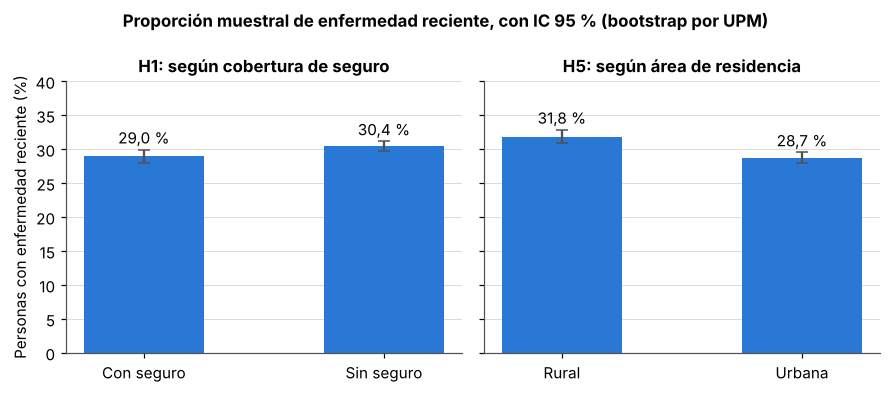

In [13]:
# Prevalencias con IC 95 % robusto por grupo (bootstrap por UPM) para H1 y H5
def prevalencia_con_ic(mascara):
    r = remuestreo.ic_bootstrap(np.mean, y[mascara], conglomerados=df.loc[mascara, "UPM"])
    return r["estimacion"] * 100, r["inf"] * 100, r["sup"] * 100


paneles = {
    "H1: según cobertura de seguro": [("Con seguro", (df["tiene_seguro"] == 1).to_numpy()), ("Sin seguro", (df["tiene_seguro"] == 0).to_numpy())],
    "H5: según área de residencia": [("Rural", (df["area"] == "Rural").to_numpy()), ("Urbana", (df["area"] == "Urbana").to_numpy())],
}
fig, ejes = plt.subplots(1, 2, figsize=(8.2, 3.6), sharey=True)
for eje, (titulo, grupos) in zip(ejes, paneles.items()):
    for i, (etiqueta, mascara) in enumerate(grupos):
        est, inf, sup = prevalencia_con_ic(mascara)
        eje.bar(i, est, width=0.5, color=datos.AZUL)
        eje.errorbar(i, est, yerr=[[est - inf], [sup - est]], color=datos.GRIS, capsize=4, linewidth=1.5)
        eje.annotate(f"{est:.1f} %".replace(".", ","), (i, sup), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=10)
    eje.set_xticks(range(len(grupos)), [g[0] for g in grupos])
    eje.set_title(titulo)
    eje.grid(axis="x", visible=False)
    eje.set_ylim(0, 40)
ejes[0].set_ylabel("Personas con enfermedad reciente (%)")
fig.suptitle("Proporción muestral de enfermedad reciente, con IC 95 % (bootstrap por UPM)", fontweight="bold", fontsize=11)
fig.tight_layout()
datos.guardar_figura(fig, "f2_02_h1_h5_prevalencias.png")
plt.show()

**Interpretación del gráfico.** Las barras parten de cero para no exagerar las diferencias. Entre personas con y sin seguro los intervalos casi se tocan (diferencia de 1,45 p.p.). Entre áreas la separación es clara: 31,8 % en el área rural frente a 28,7 % en la urbana.

**Resultado de H5.** La proporción de enfermedad reciente es 3,11 puntos porcentuales mayor en el área rural.

- **Análisis clásico:** z = 8,00; p < 0,001.
- **Análisis robusto a conglomerados:** z = 4,69; p < 0,001; IC 95 % por bootstrap de 1,8 a 4,4 p.p. El estadístico baja de 8,00 a 4,69 al reconocer que el área es una característica de la UPM: el efecto de diseño de esta diferencia es 2,9, es decir, la muestra informa como si fueran unas 19.700 personas independientes y no 57.109. La conclusión no cambia.
- **Sensibilidad al trimestre:** entre personas entrevistadas en el mismo trimestre la diferencia es de 3,20 p.p. (IC 95 % robusto: 1,92 a 4,47). El reparto desigual del área en el año no explica el resultado.
- **Tamaño del efecto:** h de Cohen = 0,07 (trivial según la convención de Cohen). Riesgo relativo 1,11.

**En lenguaje llano.** En el campo, de cada 100 personas unas 32 reportaron haber estado enfermas en los últimos 90 días; en las ciudades, unas 29. La diferencia es real (es muy difícil atribuirla al azar) pero modesta.

**Significancia frente a relevancia.** Estadísticamente el resultado es contundente. En términos estandarizados el efecto es chico. Aun así, una diferencia de 3 puntos porcentuales en una proporción que ronda el 30 % puede ser relevante para planificar servicios de salud, aunque no sirva para predecir casos individuales.

**Posible variable de confusión.** El área rural concentra hogares de menores ingresos, y el ingreso también se asocia con la enfermedad (H3). No puede afirmarse que vivir en el área rural cause más enfermedad: la diferencia puede reflejar nivel socioeconómico, acceso a agua y saneamiento, o estructura de edades. El modelo de H6 incluye área y quintil a la vez para separar ambos efectos.

In [14]:
ruta = registro.guardar()
print("Resultados guardados en:", ruta.relative_to(RAIZ))
registro.tabla()[["id", "prueba", "n", "valor_estadistico", "p_clasico", "p_robusto", "valor_efecto", "magnitud", "ic_inf", "ic_sup"]]

Resultados guardados en: output/fase2/contrastes_parte1.csv


,id,prueba,n,valor_estadistico,p_clasico,p_robusto,valor_efecto,magnitud,ic_inf,ic_sup
0,H1,z de dos proporciones,57109,-3.3339,0.0009,0.0105,-0.0317,trivial,-2.5357,-0.3198
1,H5,z de dos proporciones,57109,8.0037,1.207e-15,2.754e-06,0.0677,trivial,1.8411,4.4196
